# Studi Kasus Klasifikasi: Diagnosis Kanker Payudara (Ganas vs Jinak) dengan Machine Learning

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI Machine Learning Repository

## 1. Latar Belakang & Permasalahan
Kanker payudara adalah salah satu kanker yang paling sering terdiagnosis pada perempuan. Ketika ditemukan benjolan, dokter dapat mengambil sampel sel dengan **Fine Needle Aspirate (FNA)**, lalu sel diamati di bawah mikroskop. Penilaian manual ini subjektif dan bergantung pada pengalaman ahli patologi.

**Permasalahan:** Bagaimana membangun model yang, berdasarkan ciri-ciri inti sel (ukuran, bentuk, tekstur) dari citra FNA, dapat mengklasifikasikan tumor sebagai **ganas (Malignant, M)** atau **jinak (Benign, B)** secara cepat, konsisten, dan akurat sebagai *alat bantu keputusan* bagi tenaga medis?

**Jenis tugas:** Klasifikasi biner (M / B).

## 2. Sumber Data & Rujukan
* Dataset: *Breast Cancer Wisconsin (Diagnostic)*, UCI ML Repository (ID 17), lisensi CC BY 4.0 – https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic
* Donor/Pembuat: Dr. William H. Wolberg (Univ. of Wisconsin Hospitals), W. Nick Street, dan Olvi L. Mangasarian (Univ. of Wisconsin), didonasikan 1995.
* Makalah asli: Street, W.N., Wolberg, W.H., & Mangasarian, O.L. (1993). *Nuclear feature extraction for breast tumor diagnosis.* IS&T/SPIE Symposium on Electronic Imaging, vol. 1905, hlm. 861–870.
* Makalah terkait: Wolberg, W.H., Street, W.N., & Mangasarian, O.L. (1994). *Machine learning techniques to diagnose breast cancer from fine-needle aspirates.* Cancer Letters 77, 163–171.
* Berkas CSV pada tugas ini diekspor dari salinan dataset yang sama di *scikit-learn* (`sklearn.datasets.load_breast_cancer`), dengan label dikembalikan ke format asli UCI (M/B).



### 2.1 Penjelasan Dataset

**Gambaran umum.** Dataset ini berisi hasil pemeriksaan *Fine Needle Aspirate* (FNA), yaitu pengambilan sampel sel dari benjolan payudara dengan jarum halus. Sampel difoto secara digital, lalu inti sel pada citra disegmentasi dan dianalisis dengan perangkat lunak khusus untuk menghitung ciri bentuk dan teksturnya. Setiap baris adalah **satu pasien**, setiap kolom adalah **satu ciri hasil pengukuran**. Diagnosis (label) ditetapkan oleh pemeriksaan medis, sehingga dataset ini termasuk *supervised learning*.

| Aspek | Keterangan |
|---|---|
| Jumlah data | 569 pasien (baris) |
| Jumlah kolom | 31 = 1 label (`diagnosis`) + 30 fitur numerik |
| Variabel target | `diagnosis`: **M** = Malignant (ganas), **B** = Benign (jinak) |
| Distribusi kelas | B = 357 (62,7%), M = 212 (37,3%) → sedikit tidak seimbang |
| Tipe fitur | Seluruhnya numerik kontinu (*real*) |
| Missing value | Tidak ada |
| Asal data | Rumah sakit University of Wisconsin, Madison (AS); didonasikan ke UCI tahun 1995 |

**Struktur 30 fitur.** Ada **10 ciri dasar inti sel**, masing-masing dihitung dalam **3 bentuk statistik**, sehingga 10 × 3 = 30 fitur:
* `mean_...` : nilai rata-rata ciri tersebut dari semua inti sel pada satu citra,
* `..._error` : galat standar (*standard error*), menunjukkan keragaman antar inti sel,
* `worst_...` : rata-rata dari tiga nilai terbesar (terburuk) pada citra tersebut.

Contoh: `mean_radius` = rata-rata radius inti sel, `radius_error` = galat standar radius, `worst_radius` = radius terbesar (rata-rata dari tiga nilai terbesar).

**Kamus data: 10 ciri dasar inti sel**

| Ciri dasar | Arti | Makna medis/intuitif |
|---|---|---|
| radius | rata-rata jarak dari pusat ke titik-titik di tepi inti | ukuran inti sel; sel ganas cenderung lebih besar |
| texture | simpangan baku nilai skala abu-abu | keseragaman isi inti; tekstur tidak seragam → tanda kelainan |
| perimeter | keliling inti sel | ukuran inti sel |
| area | luas inti sel | ukuran inti sel |
| smoothness | variasi lokal panjang radius | kehalusan tepi; tepi kasar → variasi tinggi |
| compactness | perimeter² / area − 1,0 | tingkat "kepadatan" bentuk |
| concavity | tingkat keparahan bagian cekung pada kontur | seberapa dalam lekukan ke dalam |
| concave points | jumlah titik cekung pada kontur | seberapa banyak lekukan; sel ganas lebih bergerigi |
| symmetry | kesimetrisan bentuk inti | bentuk tidak simetris → tidak normal |
| fractal dimension | "coastline approximation" − 1 | kerumitan garis tepi inti sel |

**Catatan penggunaan.**
* Fitur berbeda skala (mis. `mean_area` ribuan, `mean_smoothness` ±0,1), sehingga perlu **standardisasi** sebelum dipakai algoritma berbasis jarak (KNN, SVM) atau regularisasi (Logistic Regression).
* Banyak fitur saling berkorelasi tinggi (radius, perimeter, dan area saling terkait secara geometris), sehingga akan terlihat jelas pada heatmap korelasi.
* Kelas sedikit tidak seimbang, jadi evaluasi tidak cukup memakai akurasi; digunakan juga precision, recall, F1, dan ROC-AUC.
* Berkas yang dipakai: `wdbc_breast_cancer.csv` (kolom pertama `diagnosis`, 30 kolom berikutnya fitur). Kolom ID pasien tidak ada pada salinan ini.


In [1]:
import pandas as pd
# Kamus data ringkas: 10 ciri dasar x 3 bentuk statistik = 30 fitur
ciri_dasar = ['radius','texture','perimeter','area','smoothness',
              'compactness','concavity','concave_points','symmetry','fractal_dimension']
kamus = pd.DataFrame({
    'Ciri dasar': ciri_dasar,
    'Kolom mean': ['mean_' + c for c in ciri_dasar],
    'Kolom error': [c + '_error' for c in ciri_dasar],
    'Kolom worst': ['worst_' + c for c in ciri_dasar]})
kamus

,Ciri dasar,Kolom mean,Kolom error,Kolom worst
0,radius,mean_radius,radius_error,worst_radius
1,texture,mean_texture,texture_error,worst_texture
2,perimeter,mean_perimeter,perimeter_error,worst_perimeter
3,area,mean_area,area_error,worst_area
4,smoothness,mean_smoothness,smoothness_error,worst_smoothness
5,compactness,mean_compactness,compactness_error,worst_compactness
6,concavity,mean_concavity,concavity_error,worst_concavity
7,concave_points,mean_concave_points,concave_points_error,worst_concave_points
8,symmetry,mean_symmetry,symmetry_error,worst_symmetry
9,fractal_dimension,mean_fractal_dimension,fractal_dimension_error,worst_fractal_dimension


## 3. Metode Klasifikasi yang Dibandingkan
Logistic Regression, K-Nearest Neighbors, Decision Tree, Support Vector Machine (SVM), dan Random Forest. Model terbaik dipilih lewat *cross-validation* lalu diuji pada data uji yang tidak pernah dilihat model.


## 4. Tahapan Penerapan
### 4.1 Import library & muat data mentah

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, RocCurveDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [3]:
# Muat dataset mentah.
# Jika file tidak ditemukan, otomatis dimuat dari salinan dataset di scikit-learn.
import os
if os.path.exists('wdbc_breast_cancer.csv'):
    df = pd.read_csv('wdbc_breast_cancer.csv')
else:
    from sklearn.datasets import load_breast_cancer
    d = load_breast_cancer()
    df = pd.DataFrame(d.data, columns=[n.replace(' ', '_') for n in d.feature_names])
    df.insert(0, 'diagnosis', pd.Series(d.target).map({0: 'M', 1: 'B'}))
print(df.shape)
df.head()

(569, 31)


,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### 4.2 Eksplorasi data (EDA)

In [4]:
print(df.info())
print('\nMissing value total :', df.isna().sum().sum())
print('Baris duplikat      :', df.duplicated().sum())
print('\nDistribusi kelas:')
print(df['diagnosis'].value_counts())
print((df['diagnosis'].value_counts(normalize=True)*100).round(1))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   mean_radius              569 non-null    float64
 2   mean_texture             569 non-null    float64
 3   mean_perimeter           569 non-null    float64
 4   mean_area                569 non-null    float64
 5   mean_smoothness          569 non-null    float64
 6   mean_compactness         569 non-null    float64
 7   mean_concavity           569 non-null    float64
 8   mean_concave_points      569 non-null    float64
 9   mean_symmetry            569 non-null    float64
 10  mean_fractal_dimension   569 non-null    float64
 11  radius_error             569 non-null    float64
 12  texture_error            569 non-null    float64
 13  perimeter_error          569 non-null    float64
 14  area_error               5

In [5]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean_radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean_texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean_perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean_area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean_smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean_compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean_concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean_concave_points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean_symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean_fractal_dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


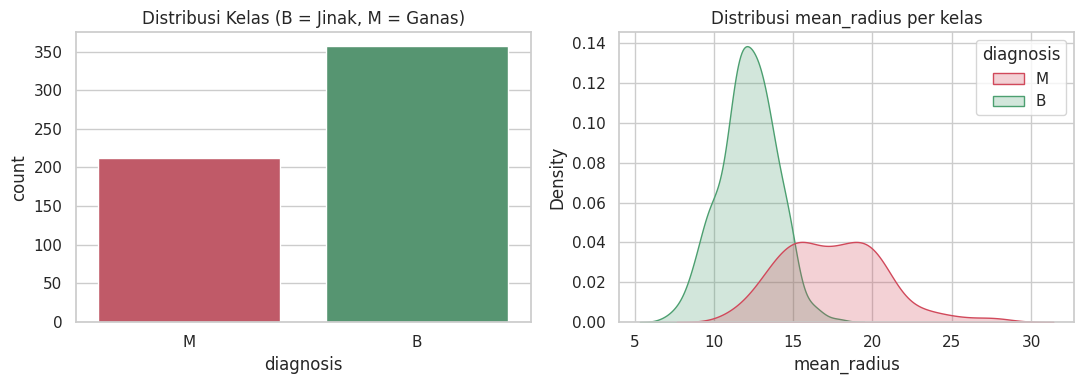

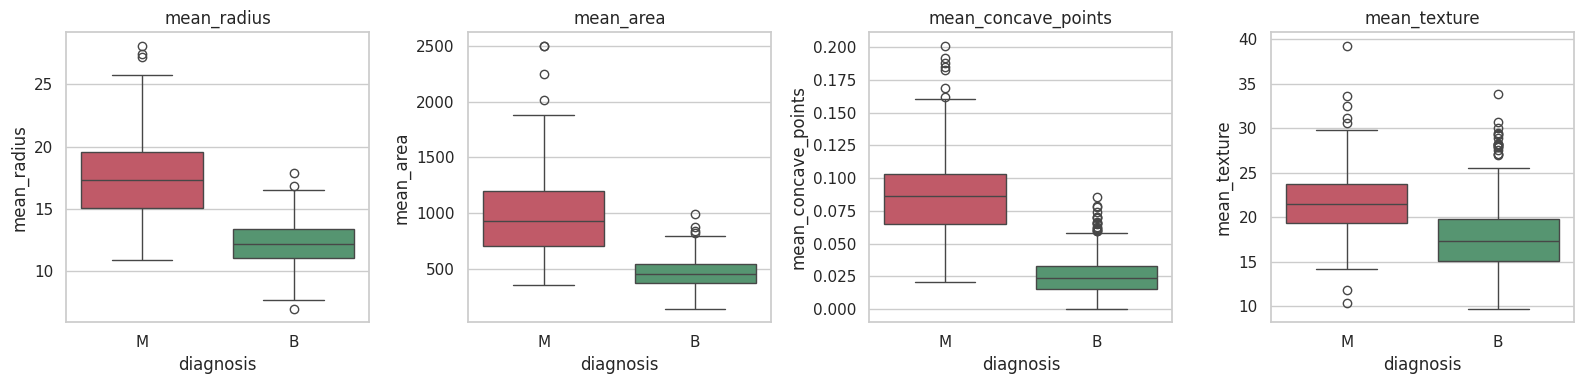

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='diagnosis', data=df, ax=ax[0], palette={'B':'#4C9F70','M':'#D1495B'})
ax[0].set_title('Distribusi Kelas (B = Jinak, M = Ganas)')
fitur = ['mean_radius','mean_area','mean_concave_points','mean_texture']
for f in fitur[:1]:
    sns.kdeplot(data=df, x=f, hue='diagnosis', fill=True, ax=ax[1], palette={'B':'#4C9F70','M':'#D1495B'})
ax[1].set_title('Distribusi mean_radius per kelas')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for a, f in zip(axes, fitur):
    sns.boxplot(x='diagnosis', y=f, data=df, ax=a, palette={'B':'#4C9F70','M':'#D1495B'})
    a.set_title(f)
plt.tight_layout(); plt.show()

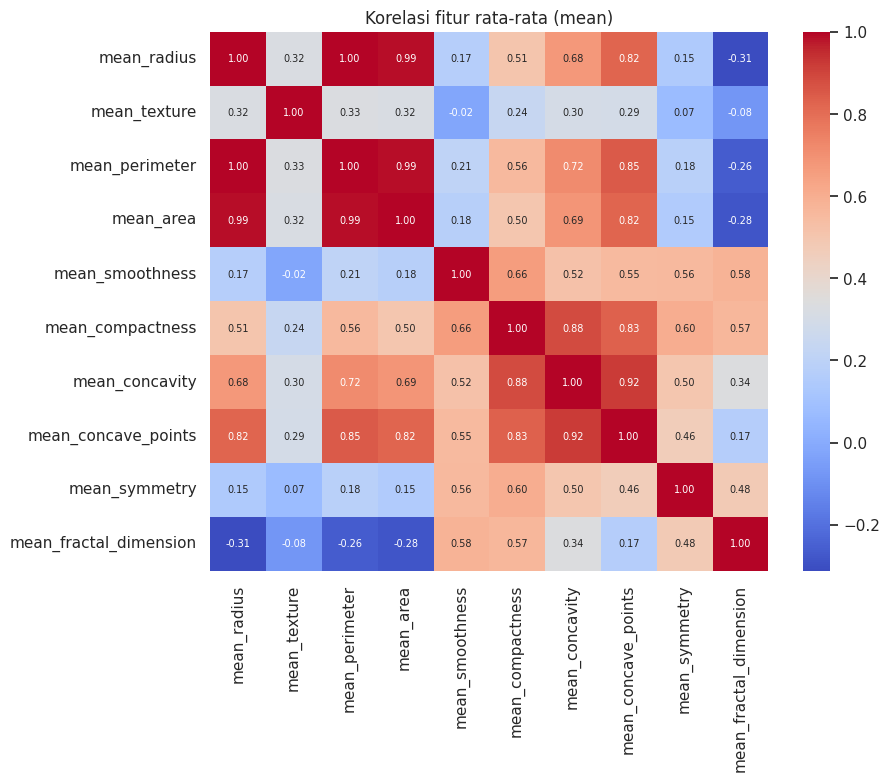

In [7]:
# Korelasi antar fitur 'mean'
mean_cols = [c for c in df.columns if c.startswith('mean_')]
plt.figure(figsize=(9, 7))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size':7})
plt.title('Korelasi fitur rata-rata (mean)'); plt.show()

### 4.3 Pra-pemrosesan data
* Label `M` → **1** (kelas positif = ganas), `B` → **0**. Kelas ganas dijadikan positif karena kesalahan melewatkan kanker (*false negative*) adalah yang paling berbahaya.
* Data dibagi 80% latih / 20% uji dengan **stratifikasi** agar proporsi kelas terjaga.
* Standardisasi fitur (`StandardScaler`) dimasukkan ke dalam **Pipeline** agar tidak terjadi *data leakage* (scaler hanya belajar dari data latih pada setiap lipatan).

In [8]:
X = df.drop(columns='diagnosis')
y = (df['diagnosis'] == 'M').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)
print('Proporsi ganas (latih/uji): %.3f / %.3f' % (y_train.mean(), y_test.mean()))

Data latih: (455, 30) | Data uji: (114, 30)
Proporsi ganas (latih/uji): 0.374 / 0.368


### 4.4 Pemodelan: perbandingan 5 algoritma dengan Stratified 5-Fold Cross-Validation

In [9]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    'KNN':                 KNeighborsClassifier(n_neighbors=5),
    'Decision Tree':       DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'SVM (RBF)':           SVC(probability=True, random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

rows = []
for name, clf in models.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('clf', clf)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'Model': name, **{m: res['test_'+m].mean() for m in scoring},
                 'f1_std': res['test_f1'].std()})
cv_table = pd.DataFrame(rows).set_index('Model').round(4).sort_values('f1', ascending=False)
cv_table

,accuracy,precision,recall,f1,roc_auc,f1_std
Model,,,,,,
Logistic Regression,0.9736,0.9771,0.9529,0.9640,0.9958,0.0207
SVM (RBF),0.9714,0.9769,0.9471,0.9610,0.9949,0.0082
KNN,0.9648,0.9875,0.9176,0.9510,0.9871,0.0263
Random Forest,0.9604,0.9584,0.9353,0.9461,0.9880,0.0226
Decision Tree,0.9077,0.8943,0.8529,0.8717,0.8875,0.0573


### 4.5 Penyetelan hyperparameter (tuning) dengan SVM

In [10]:
svm_pipe = Pipeline([('scaler', StandardScaler()), ('clf', SVC(probability=True, random_state=RANDOM_STATE))])
param_grid = {'clf__C': [0.1, 1, 10, 100],
              'clf__gamma': ['scale', 0.001, 0.01, 0.1],
              'clf__kernel': ['rbf', 'linear']}
gs = GridSearchCV(svm_pipe, param_grid, cv=cv, scoring='f1', n_jobs=-1)
gs.fit(X_train, y_train)
print('Parameter terbaik :', gs.best_params_)
print('F1 CV terbaik     : %.4f' % gs.best_score_)
best_model = gs.best_estimator_

Parameter terbaik : {'clf__C': 10, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
F1 CV terbaik     : 0.9674


### 4.6 Evaluasi akhir pada data uji (data yang belum pernah dilihat model)

In [11]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print('Accuracy  : %.4f' % accuracy_score(y_test, y_pred))
print('Precision : %.4f' % precision_score(y_test, y_pred))
print('Recall    : %.4f  (sensitivitas - kemampuan menangkap kasus ganas)' % recall_score(y_test, y_pred))
print('F1-score  : %.4f' % f1_score(y_test, y_pred))
print('ROC-AUC   : %.4f' % roc_auc_score(y_test, y_prob))
print()
print(classification_report(y_test, y_pred, target_names=['Jinak (B)', 'Ganas (M)']))

Accuracy  : 0.9737
Precision : 1.0000
Recall    : 0.9286  (sensitivitas - kemampuan menangkap kasus ganas)
F1-score  : 0.9630
ROC-AUC   : 0.9927

              precision    recall  f1-score   support

   Jinak (B)       0.96      1.00      0.98        72
   Ganas (M)       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



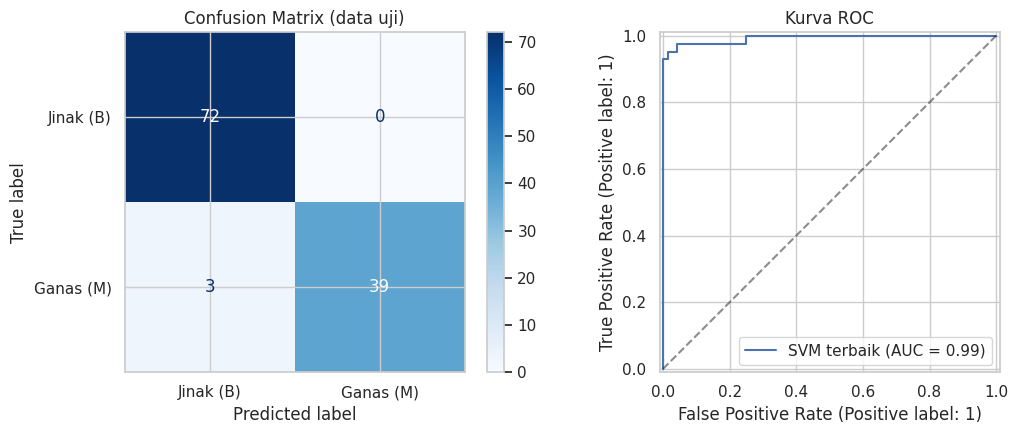

TP=39  TN=72  FP=0  FN=3


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Jinak (B)','Ganas (M)'],
                                        cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix (data uji)')
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1], name='SVM terbaik')
ax[1].plot([0,1],[0,1],'k--', alpha=.5); ax[1].set_title('Kurva ROC')
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'TP={tp}  TN={tn}  FP={fp}  FN={fn}')

### 4.7 Interpretasi: fitur apa yang paling berpengaruh?

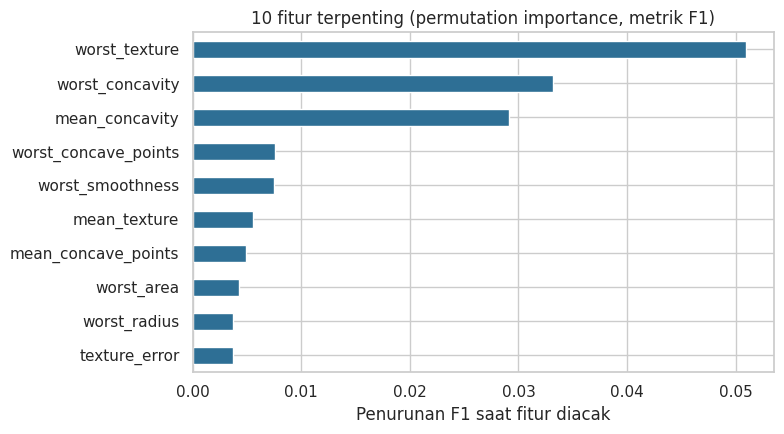

,0
worst_texture,0.0510
worst_concavity,0.0332
mean_concavity,0.0291
worst_concave_points,0.0075
worst_smoothness,0.0074
mean_texture,0.0055
mean_concave_points,0.0050
worst_area,0.0043
worst_radius,0.0037
texture_error,0.0037


In [13]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=30,
                              random_state=RANDOM_STATE, scoring='f1')
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4.5))
imp[::-1].plot(kind='barh', color='#2E6F95')
plt.title('10 fitur terpenting (permutation importance, metrik F1)')
plt.xlabel('Penurunan F1 saat fitur diacak'); plt.tight_layout(); plt.show()
imp.round(4)

### 4.8 Pembanding: semua model pada data uji

In [14]:
rows = []
for name, clf in models.items():
    p = Pipeline([('scaler', StandardScaler()), ('clf', clf)]).fit(X_train, y_train)
    yp, ypr = p.predict(X_test), p.predict_proba(X_test)[:,1]
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, yp), 'Precision': precision_score(y_test, yp),
                 'Recall': recall_score(y_test, yp), 'F1': f1_score(y_test, yp), 'ROC-AUC': roc_auc_score(y_test, ypr)})
rows.append({'Model': 'SVM (tuned)', 'Accuracy': accuracy_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred),
             'Recall': recall_score(y_test, y_pred), 'F1': f1_score(y_test, y_pred), 'ROC-AUC': roc_auc_score(y_test, y_prob)})
pd.DataFrame(rows).set_index('Model').round(4).sort_values('F1', ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.9737,1.0000,0.9286,0.9630,0.9944
SVM (RBF),0.9737,1.0000,0.9286,0.9630,0.9947
SVM (tuned),0.9737,1.0000,0.9286,0.9630,0.9927
Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960
KNN,0.9561,0.9744,0.9048,0.9383,0.9823
Decision Tree,0.9211,0.9459,0.8333,0.8861,0.9448


In [15]:
# Contoh prediksi untuk 5 pasien dari data uji
contoh = X_test.sample(5, random_state=1)
hasil = pd.DataFrame({
    'Diagnosis asli': y_test.loc[contoh.index].map({0:'Jinak',1:'Ganas'}),
    'Prediksi model': best_model.predict(contoh),
    'Probabilitas ganas': best_model.predict_proba(contoh)[:,1].round(3)})
hasil['Prediksi model'] = hasil['Prediksi model'].map({0:'Jinak',1:'Ganas'})
hasil

,Diagnosis asli,Prediksi model,Probabilitas ganas
125,Jinak,Jinak,0.004
111,Jinak,Jinak,0.013
410,Jinak,Jinak,0.184
553,Jinak,Jinak,0.008
5,Ganas,Ganas,0.785


## 5. Hasil, Pembahasan, dan Manfaat
**Hasil (data uji 114 pasien, `random_state=42`).**
* Semua algoritma mencapai akurasi di atas 92%. Pada data uji, SVM (tuned, C=10, kernel RBF), SVM default, dan Random Forest sama-sama akurasi **97,4%**, precision **100%**, recall **92,9%**, F1 **0,963**; ROC-AUC SVM tuned **0,993**. Decision Tree paling lemah (akurasi 92,1%, recall 83,3%).
* Confusion matrix model SVM tuned: **TP=39, TN=72, FP=0, FN=3**. Tidak ada tumor jinak yang salah dicap ganas, namun **3 dari 42 kasus ganas terlewat**, yaitu risiko yang perlu diperhatikan dalam penggunaan klinis (bisa diperbaiki dengan menurunkan ambang probabilitas dan menerima lebih banyak *false positive*).
* Berdasarkan *permutation importance*, fitur paling berpengaruh adalah **worst_texture, worst_concavity, mean_concavity**, lalu worst_concave_points dan worst_smoothness: sel ganas cenderung memiliki tekstur inti yang tidak seragam dan kontur yang lebih cekung/tidak beraturan.
* Catatan: karena data uji kecil, selisih antar model teratas (1 kasus = ±0,9%) tidak bermakna secara statistik; perbandingan yang lebih andal ada pada tabel cross-validation.

**Manfaat.**
1. **Alat bantu keputusan klinis** – memberi *second opinion* objektif dan konsisten bagi ahli patologi.
2. **Efisiensi** – prediksi dalam hitungan milidetik, membantu prioritas pemeriksaan pada fasilitas dengan tenaga ahli terbatas.
3. **Deteksi dini** – recall tinggi berarti sedikit kasus ganas terlewat sehingga penanganan bisa lebih cepat.
4. **Interpretabilitas** – analisis fitur penting membantu validasi hasil model dengan pengetahuan medis.

## 6. Keterbatasan
* Hanya 569 pasien dari satu institusi, sehingga belum tentu berlaku pada populasi/alat/prosedur lain (perlu validasi eksternal).
* Fitur dihitung dari citra yang sudah diproses; model tidak membaca citra mentah.
* Kelas sedikit tidak seimbang (63% jinak : 37% ganas) – karena itu recall dan F1 dilaporkan, bukan hanya akurasi.
* Model ini **bukan pengganti dokter**; harus dipakai sebagai pendukung keputusan, dan *false negative* tetap berisiko.
* Ukuran data uji kecil (114), sehingga selisih beberapa kasus mengubah metrik cukup besar.

## 7. Daftar Pustaka
1. Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic
2. Street, W.N., Wolberg, W.H., & Mangasarian, O.L. (1993). Nuclear feature extraction for breast tumor diagnosis. *IS&T/SPIE International Symposium on Electronic Imaging*, 1905, 861–870.
3. Wolberg, W.H., Street, W.N., & Mangasarian, O.L. (1994). Machine learning techniques to diagnose breast cancer from fine-needle aspirates. *Cancer Letters*, 77, 163–171.
4. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825–2830.
